## Celda 1 - cargar y dividir en entrenamiento (2024) y prueba (2025)

In [3]:
import pandas as pd
import numpy as np
import time
from pathlib import Path

FIGURAS = Path("figuras")
tabla = pd.read_parquet("procesado/tabla_modelo.parquet")
tabla = tabla.sort_values(["hora_inicio", "origen"]).reset_index(drop=True)

train = tabla[tabla["anio"] == 2024]
test = tabla[tabla["anio"] == 2025]
y_train, y_test = train["salidas"], test["salidas"]

VARS_LINEAL = ["origen", "hora", "dia_semana", "mes", "festivo"]
VARS_ARBOL = ["hora", "dia_semana", "mes", "fin_de_semana", "festivo",
              "latitude", "longitude", "dpcapacity"]

print(f"Entrenamiento (2024): {len(train):,} filas")
print(f"Prueba (2025):        {len(test):,} filas")

Entrenamiento (2024): 219,600 filas
Prueba (2025):        219,000 filas


## Celda 2 - métricas y modelos base

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

resultados = []

def evaluar(nombre, conjunto, y_real, y_pred):
    resultados.append({
        "modelo": nombre,
        "conjunto": conjunto,
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred),
    })

promedios = train.groupby(["origen", "hora", "dia_semana"])["salidas"].mean().rename("pred")

def predecir_base(df):
    return df.join(promedios, on=["origen", "hora", "dia_semana"])["pred"].fillna(y_train.mean())

evaluar("Base (promedio histórico)", "entrenamiento", y_train, predecir_base(train))
evaluar("Base (promedio histórico)", "prueba", y_test, predecir_base(test))
pd.DataFrame(resultados).round(3)

,modelo,conjunto,MAE,RMSE,R2
0,Base (promedio histórico),entrenamiento,1.983,2.866,0.708
1,Base (promedio histórico),prueba,2.169,3.363,0.621


## Celda 3 - Deinifir y entrenar los 3 modelos

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

lineal = Pipeline([
    ("prep", ColumnTransformer(
        [("onehot", OneHotEncoder(handle_unknown="ignore"), ["origen", "hora", "dia_semana", "mes"])],
        remainder="passthrough")),          # 'festivo' pasa tal cual (ya es 0/1)
    ("modelo", LinearRegression()),
])

modelos = {
    "Regresión lineal": (lineal, VARS_LINEAL),
    "Árbol de decisión": (DecisionTreeRegressor(random_state=42), VARS_ARBOL),
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), VARS_ARBOL),
}

for nombre, (modelo, variables) in modelos.items():
    t0 = time.time()
    modelo.fit(train[variables], y_train)
    evaluar(nombre, "entrenamiento", y_train, modelo.predict(train[variables]))
    evaluar(nombre, "prueba", y_test, modelo.predict(test[variables]))
    print(f"{nombre}: entrenado en {time.time() - t0:.1f} s")

tabla_resultados = pd.DataFrame(resultados).round(3)
tabla_resultados

Regresión lineal: entrenado en 0.3 s
Árbol de decisión: entrenado en 0.6 s
Random Forest: entrenado en 11.4 s


,modelo,conjunto,MAE,RMSE,R2
0,Base (promedio histórico),entrenamiento,1.983,2.866,0.708
1,Base (promedio histórico),prueba,2.169,3.363,0.621
2,Regresión lineal,entrenamiento,2.739,4.017,0.427
3,Regresión lineal,prueba,2.805,4.247,0.396
4,Árbol de decisión,entrenamiento,1.603,2.328,0.808
5,Árbol de decisión,prueba,2.322,3.559,0.576
6,Random Forest,entrenamiento,1.621,2.336,0.806
7,Random Forest,prueba,2.315,3.548,0.578


## Celda 4 - validacion cruzada temporal en 2024

In [6]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

tscv = TimeSeriesSplit(n_splits=5)
filas_cv = []

for nombre, (modelo, variables) in modelos.items():
    t0 = time.time()
    cv = cross_validate(modelo, train[variables], y_train, cv=tscv,
                        scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    filas_cv.append({
        "modelo": nombre,
        "MAE (media)": -cv["test_neg_mean_absolute_error"].mean(),
        "MAE (desv.)": cv["test_neg_mean_absolute_error"].std(),
        "RMSE (media)": -cv["test_neg_root_mean_squared_error"].mean(),
        "R2 (media)": cv["test_r2"].mean(),
        "R2 (desv.)": cv["test_r2"].std(),
    })
    print(f"{nombre}: {time.time() - t0:.1f} s")

pd.DataFrame(filas_cv).round(3)

Regresión lineal: 0.6 s
Árbol de decisión: 1.3 s
Random Forest: 20.3 s


,modelo,MAE (media),MAE (desv.),RMSE (media),R2 (media),R2 (desv.)
0,Regresión lineal,2.784,0.082,3.998,0.419,0.015
1,Árbol de decisión,2.287,0.100,3.284,0.606,0.046
2,Random Forest,2.189,0.034,3.129,0.643,0.028


## Celda 5 - grafica de prediccion contra valores reales

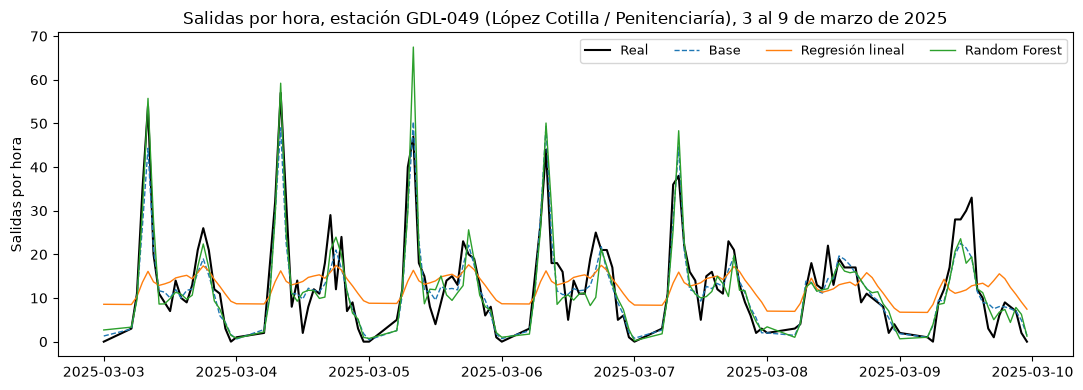

In [7]:
import matplotlib.pyplot as plt

semana = test[(test["origen"] == 51) &
              (test["hora_inicio"] >= "2025-03-03") & (test["hora_inicio"] < "2025-03-10")]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(semana["hora_inicio"], semana["salidas"], color="black", lw=1.5, label="Real")
ax.plot(semana["hora_inicio"], predecir_base(semana), lw=1, ls="--", label="Base")
for nombre in ("Regresión lineal", "Random Forest"):
    modelo, variables = modelos[nombre]
    ax.plot(semana["hora_inicio"], modelo.predict(semana[variables]), lw=1, label=nombre)
ax.set(title="Salidas por hora, estación GDL-049 (López Cotilla / Penitenciaría), 3 al 9 de marzo de 2025",
       ylabel="Salidas por hora")
ax.legend(ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "prediccion_vs_real.png", dpi=150)
plt.show()

## celda 6 - importancia de las variables

festivo          0.019
fin_de_semana    0.032
dia_semana       0.085
mes              0.090
latitude         0.092
longitude        0.122
dpcapacity       0.132
hora             0.427


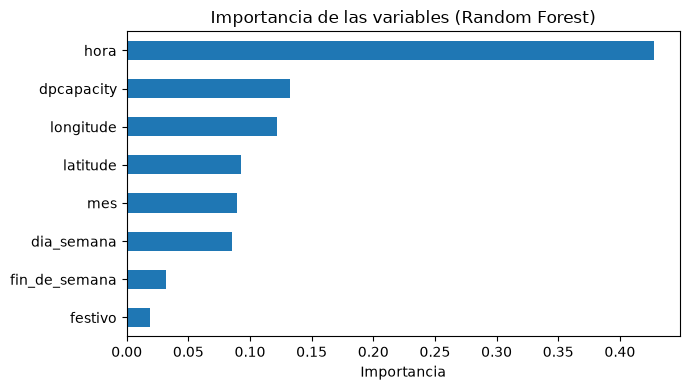

In [8]:
rf = modelos["Random Forest"][0]
importancias = pd.Series(rf.feature_importances_, index=VARS_ARBOL).sort_values()
print(importancias.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
importancias.plot.barh(ax=ax)
ax.set(title="Importancia de las variables (Random Forest)", xlabel="Importancia")
fig.tight_layout()
fig.savefig(FIGURAS / "importancia_variables.png", dpi=150)
plt.show()

## celda 7 - Grid search sobre el random forest

In [9]:
from sklearn.model_selection import GridSearchCV

parametros = {
    "min_samples_leaf": [5, 20, 50, 100],
    "max_depth": [None, 12, 20],
    "max_features": [1.0, 0.5],
}
t0 = time.time()
busqueda_rf = GridSearchCV(
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    parametros, cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_absolute_error", n_jobs=1, verbose=1)
busqueda_rf.fit(train[VARS_ARBOL], y_train)
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")
print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print(f"MAE en validación cruzada: {-busqueda_rf.best_score_:.3f}")

top = pd.DataFrame(busqueda_rf.cv_results_)[["params", "mean_test_score", "std_test_score"]]
top["MAE"] = -top["mean_test_score"]
print(top.sort_values("MAE")[["params", "MAE", "std_test_score"]].head(8).to_string(index=False))

rf_opt = busqueda_rf.best_estimator_
evaluar("Random Forest optimizado", "entrenamiento", y_train, rf_opt.predict(train[VARS_ARBOL]))
evaluar("Random Forest optimizado", "prueba", y_test, rf_opt.predict(test[VARS_ARBOL]))
pd.DataFrame(resultados).round(3).tail(2)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Tiempo: 2.9 min
Mejores hiperparámetros: {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 5}
MAE en validación cruzada: 2.044
                                                          params      MAE  std_test_score
   {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 5} 2.044410        0.024842
  {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 20} 2.044857        0.014305
{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 20} 2.045186        0.014334
 {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5} 2.046723        0.025448
  {'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 20} 2.048674        0.023415
{'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 20} 2.048724        0.023496
   {'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 5} 2.068244        0.026342
 {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 5} 2.072430        0.

,modelo,conjunto,MAE,RMSE,R2
8,Random Forest optimizado,entrenamiento,1.754,2.506,0.777
9,Random Forest optimizado,prueba,2.174,3.354,0.623


## celda 8 - Seleccion de caracteristicas

In [10]:
from sklearn.base import clone

VARS_SIN_MES = [v for v in VARS_ARBOL if v != "mes"]
tscv5 = TimeSeriesSplit(n_splits=5)

for etiqueta, variables in [("Con mes", VARS_ARBOL), ("Sin mes", VARS_SIN_MES)]:
    cv = cross_validate(clone(rf_opt), train[variables], y_train, cv=tscv5,
                        scoring=["neg_mean_absolute_error", "r2"])
    print(f"{etiqueta}: MAE = {-cv['test_neg_mean_absolute_error'].mean():.3f} "
          f"(± {cv['test_neg_mean_absolute_error'].std():.3f}) | R2 = {cv['test_r2'].mean():.3f}")

Con mes: MAE = 2.048 (± 0.031) | R2 = 0.689
Sin mes: MAE = 2.040 (± 0.013) | R2 = 0.690


## celda 9 - Modelo mas complejo, Gradient Boosting con pérdida poisson

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor

parametros_hgb = {
    "learning_rate": [0.05, 0.1],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [20, 100],
}
t0 = time.time()
busqueda_hgb = GridSearchCV(
    HistGradientBoostingRegressor(loss="poisson", max_iter=300, early_stopping=False, random_state=42),
    parametros_hgb, cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_absolute_error", n_jobs=1, verbose=1)
busqueda_hgb.fit(train[VARS_ARBOL], y_train)
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")
print("Mejores hiperparámetros:", busqueda_hgb.best_params_)
print(f"MAE en validación cruzada: {-busqueda_hgb.best_score_:.3f}")

hgb_opt = busqueda_hgb.best_estimator_
evaluar("Gradient Boosting (Poisson)", "entrenamiento", y_train, hgb_opt.predict(train[VARS_ARBOL]))
evaluar("Gradient Boosting (Poisson)", "prueba", y_test, hgb_opt.predict(test[VARS_ARBOL]))
pd.DataFrame(resultados).round(3).tail(2)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Tiempo: 0.8 min
Mejores hiperparámetros: {'learning_rate': 0.1, 'max_leaf_nodes': 63, 'min_samples_leaf': 100}
MAE en validación cruzada: 2.061


,modelo,conjunto,MAE,RMSE,R2
10,Gradient Boosting (Poisson),entrenamiento,1.886,2.670,0.747
11,Gradient Boosting (Poisson),prueba,2.120,3.284,0.639


## celda 10 - Comparación final

In [12]:
final = pd.DataFrame(resultados).pivot(index="modelo", columns="conjunto", values=["MAE", "RMSE", "R2"])
final = final.reindex(columns=["entrenamiento", "prueba"], level=1).round(3)
final = final.sort_values(("MAE", "prueba"))
final.to_csv("procesado/comparacion_modelos.csv")
final

MAE                 RMSE         \
conjunto                    entrenamiento prueba entrenamiento prueba   
modelo                                                                  
Gradient Boosting (Poisson)         1.886  2.120         2.670  3.284   
Base (promedio histórico)           1.983  2.169         2.866  3.363   
Random Forest optimizado            1.754  2.174         2.506  3.354   
Random Forest                       1.621  2.315         2.336  3.548   
Árbol de decisión                   1.603  2.322         2.328  3.559   
Regresión lineal                    2.739  2.805         4.017  4.247   

                                       R2         
conjunto                    entrenamiento prueba  
modelo                                            
Gradient Boosting (Poisson)         0.747  0.639  
Base (promedio histórico)           0.708  0.621  
Random Forest optimizado            0.777  0.623  
Random Forest                       0.806  0.578  
Árbol de decisión                   0.808  0.576  
Regresión lineal                    0.427  0.396

## Celda 11 - Gradient Boosting con y sin mes

In [13]:
cv_hgb = {}
for etiqueta, variables in [("Con mes", VARS_ARBOL), ("Sin mes", VARS_SIN_MES)]:
    cv = cross_validate(clone(hgb_opt), train[variables], y_train, cv=tscv5,
                        scoring=["neg_mean_absolute_error", "r2"])
    cv_hgb[etiqueta] = (variables, -cv["test_neg_mean_absolute_error"].mean())
    print(f"{etiqueta}: MAE = {-cv['test_neg_mean_absolute_error'].mean():.3f} "
          f"(± {cv['test_neg_mean_absolute_error'].std():.3f}) | R2 = {cv['test_r2'].mean():.3f}")

# Se elige con la validación cruzada (2024), no con la prueba (2025)
etiqueta_final = min(cv_hgb, key=lambda k: cv_hgb[k][1])
VARS_FINAL = cv_hgb[etiqueta_final][0]
print(f"\nVariables elegidas: {etiqueta_final} -> {VARS_FINAL}")

modelo_final = clone(hgb_opt).fit(train[VARS_FINAL], y_train)
nombre_final = f"Gradient Boosting (Poisson), {etiqueta_final.lower()}"
evaluar(nombre_final, "entrenamiento", y_train, modelo_final.predict(train[VARS_FINAL]))
evaluar(nombre_final, "prueba", y_test, modelo_final.predict(test[VARS_FINAL]))
pd.DataFrame(resultados).round(3).tail(2)

Con mes: MAE = 2.050 (± 0.037) | R2 = 0.688
Sin mes: MAE = 2.024 (± 0.012) | R2 = 0.695

Variables elegidas: Sin mes -> ['hora', 'dia_semana', 'fin_de_semana', 'festivo', 'latitude', 'longitude', 'dpcapacity']


,modelo,conjunto,MAE,RMSE,R2
12,"Gradient Boosting (Poisson), sin mes",entrenamiento,1.957,2.801,0.721
13,"Gradient Boosting (Poisson), sin mes",prueba,2.123,3.287,0.638


## Celda 12 - Grafica final

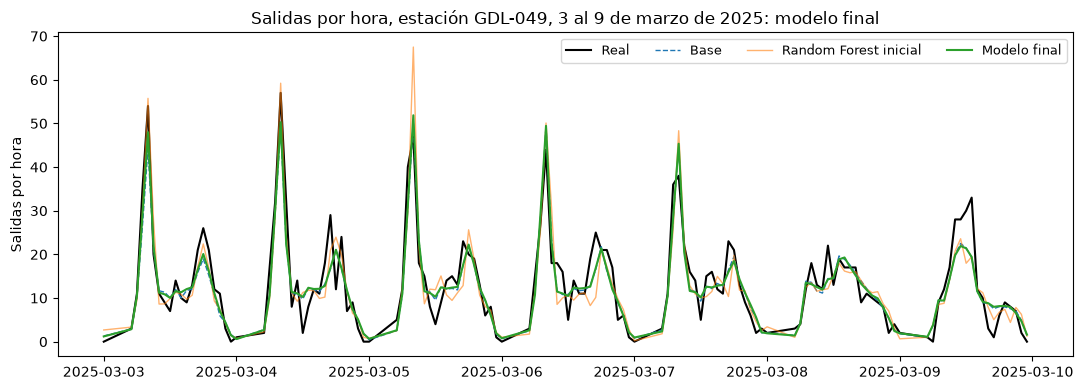

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(semana["hora_inicio"], semana["salidas"], color="black", lw=1.5, label="Real")
ax.plot(semana["hora_inicio"], predecir_base(semana), lw=1, ls="--", label="Base")
ax.plot(semana["hora_inicio"], modelos["Random Forest"][0].predict(semana[VARS_ARBOL]),
        lw=1, alpha=.6, label="Random Forest inicial")
ax.plot(semana["hora_inicio"], modelo_final.predict(semana[VARS_FINAL]), lw=1.5, label="Modelo final")
ax.set(title="Salidas por hora, estación GDL-049, 3 al 9 de marzo de 2025: modelo final",
       ylabel="Salidas por hora")
ax.legend(ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "prediccion_vs_real_final.png", dpi=150)
plt.show()

## Celda 13 - Error por hora del dia

      Salidas promedio  MAE base  MAE modelo final
hora                                              
0                 0.60      0.67              0.67
5                 0.64      0.58              0.58
6                 2.52      1.28              1.24
7                 5.77      2.08              1.97
8                 8.03      2.75              2.63
9                 5.31      2.25              2.21
10                4.81      2.02              2.00
11                5.38      2.15              2.11
12                5.62      2.23              2.20
13                6.40      2.42              2.37
14                6.84      2.42              2.37
15                7.15      2.57              2.51
16                6.64      2.44              2.38
17                7.72      2.87              2.79
18                9.55      3.79              3.68
19                8.03      3.32              3.28
20                6.20      2.64              2.60
21                4.54      2.2

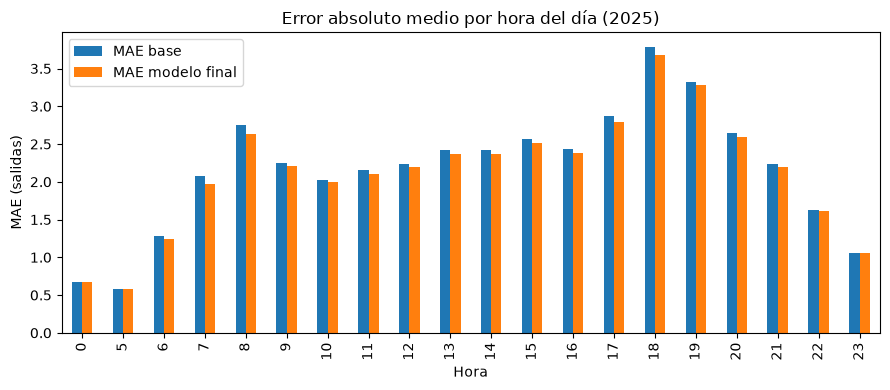

In [15]:
errores = test[["hora", "salidas"]].copy()
errores["error_final"] = (errores["salidas"] - modelo_final.predict(test[VARS_FINAL])).abs()
errores["error_base"] = (errores["salidas"] - predecir_base(test)).abs()

por_hora = errores.groupby("hora")[["salidas", "error_base", "error_final"]].mean().round(2)
por_hora.columns = ["Salidas promedio", "MAE base", "MAE modelo final"]
print(por_hora.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
por_hora[["MAE base", "MAE modelo final"]].plot.bar(ax=ax)
ax.set(title="Error absoluto medio por hora del día (2025)", xlabel="Hora", ylabel="MAE (salidas)")
fig.tight_layout()
fig.savefig(FIGURAS / "error_por_hora.png", dpi=150)
plt.show()

## Celda 14 - Tabla final actualizada

In [16]:
final = pd.DataFrame(resultados).pivot(index="modelo", columns="conjunto", values=["MAE", "RMSE", "R2"])
final = final.reindex(columns=["entrenamiento", "prueba"], level=1).round(3)
final = final.sort_values(("MAE", "prueba"))
final.to_csv("procesado/comparacion_modelos.csv")
final

MAE                 RMSE  \
conjunto                             entrenamiento prueba entrenamiento   
modelo                                                                    
Gradient Boosting (Poisson)                  1.886  2.120         2.670   
Gradient Boosting (Poisson), sin mes         1.957  2.123         2.801   
Base (promedio histórico)                    1.983  2.169         2.866   
Random Forest optimizado                     1.754  2.174         2.506   
Random Forest                                1.621  2.315         2.336   
Árbol de decisión                            1.603  2.322         2.328   
Regresión lineal                             2.739  2.805         4.017   

                                                       R2         
conjunto                             prueba entrenamiento prueba  
modelo                                                            
Gradient Boosting (Poisson)           3.284         0.747  0.639  
Gradient Boosting (Poisson), sin mes  3.287         0.721  0.638  
Base (promedio histórico)             3.363         0.708  0.621  
Random Forest optimizado              3.354         0.777  0.623  
Random Forest                         3.548         0.806  0.578  
Árbol de decisión                     3.559         0.808  0.576  
Regresión lineal                      4.247         0.427  0.396